In [8]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [9]:
def f(x):
  return 3*x**2 - 4*x +5


In [10]:
f(3.0)

20.0

In [11]:
xs = np.arange(-5,5,0.25)

In [12]:
ys=f(xs)
print(ys)

[100.      91.6875  83.75    76.1875  69.      62.1875  55.75    49.6875
  44.      38.6875  33.75    29.1875  25.      21.1875  17.75    14.6875
  12.       9.6875   7.75     6.1875   5.       4.1875   3.75     3.6875
   4.       4.6875   5.75     7.1875   9.      11.1875  13.75    16.6875
  20.      23.6875  27.75    32.1875  37.      42.1875  47.75    53.6875]


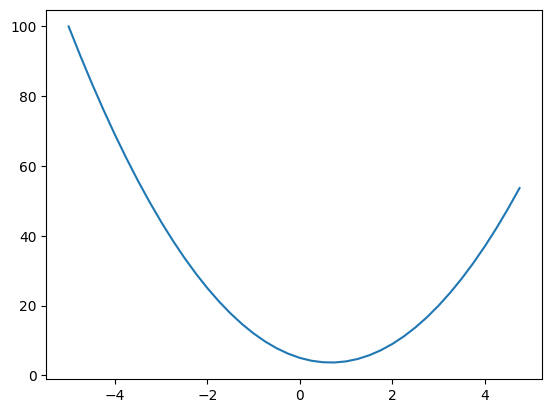

In [13]:
plt.plot(xs,ys)

In [14]:
h=0.001
x=-3.0
print(f(x+h))

43.978003


In [15]:
print (( f(x+h)-f(x))/h) #derivative or slope using derivative formula

-21.996999999998934


In [16]:
def get_derivative(f, x, h=0.001):
    return (f(x + h) - f(x)) / h

# Let's test the function at x = -3.0 with h = 0.001
deriv = get_derivative(f, -3.0, 0.001)
print(deriv)

-21.996999999998934


In [17]:
get_derivative(f,2/3,0.00000001)

0.0

In [18]:
a=eval(input("enter a"))
b=eval(input("enter b"))
c=eval(input("enter c"))
d = a*b + c
print (d)

KeyboardInterrupt: Interrupted by user

In [ ]:
d1=a*b+c
print(d1)

In [ ]:
h=0.001
a+=h
d2=a*b+c
print(d2)

In [ ]:
slope= (d2-d1)/ h
print(slope)

In [19]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * (self.data ** (other - 1))) * out.grad
        out._backward = _backward

        return out

    def __rmul__(self, other):
        return self * other

    def __radd__(self, other):
        return self + other

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

    def __neg__(self):
        return self * -1

    def __truediv__(self, other):
        return self * (other**-1)

    def __rtruediv__(self, other):
        return other * (self**-1)

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

# The Value class wraps a single number (like 2.0 or -3.0).
# It acts as a node in a mathematical expression tree, keeping track of:
# 1. The number itself (self.data)
# 2. Its gradient/derivative (self.grad)
# 3. How it was created (self._prev and self._op)
#
# ## Resources
# - micrograd github repository: https://github.com/karpathy/micrograd


In [20]:
a = Value(2.0, label='a')
b = Value(3.0, label='b')
c = Value(4.0, label='c')

# Let's perform the operations using standard operators
k = a * b; k.label = 'k'
d = k + c; d.label = 'd'

print(f"Value of d: {d.data}")

Value of d: 10.0


In [21]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        label_str = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad) if n.label else "{ data %.4f | grad %.4f }" % (n.data, n.grad)
        dot.node(name = uid, label = label_str, shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this op node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

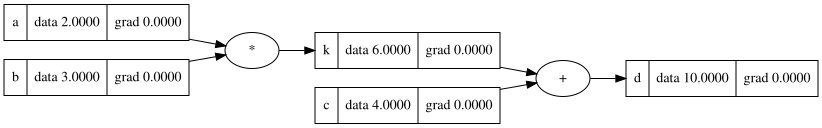

In [68]:
draw_dot(d)
# grad at each place is denoting derivative of the output with respect to that element.

In [22]:
def lol():
  a = Value(2.0, label='a')
  b = Value(3.0, label='b')
  c = Value(4.0, label='c')

  # Let's perform the operations using standard operators
  k = a * b; k.label = 'k'
  d = k + c; d.label = 'd'

To derive the equation x1.grad = w1.data * x1w1.grad, we use the Chain Rule from calculus applied to a computational graph node.1. Define the Forward OperationIn the multiplication node (*), the output value ($z$) is computed as the product of its two inputs, $x_1$ and $w_1$:$$z = x_1 \cdot w_1$$(Here, $z$ corresponds to the x1*w1 node).2. Apply the Chain RuleWe want to find how a change in the input $x_1$ affects the final loss or output $L$ of the entire network. By the chain rule:$$\frac{\partial L}{\partial x_1} = \frac{\partial L}{\partial z} \cdot \frac{\partial z}{\partial x_1}$$3. Evaluate the ComponentsIncoming Gradient ($\frac{\partial L}{\partial z}$): This is the gradient flowing backward into the multiplication node from downstream operations. In micrograd, this is stored as x1w1.grad.Local Derivative ($\frac{\partial z}{\partial x_1}$): Differentiating the forward equation $z = x_1 \cdot w_1$ with respect to $x_1$ gives:$$\frac{\partial z}{\partial x_1} = w_1$$This represents the current value of the weight, stored as w1.data.4. Combine into the Final EquationSubstituting the local derivative and the incoming gradient back into the chain rule formula gives:$$\frac{\partial L}{\partial x_1} = w_1 \cdot \frac{\partial L}{\partial z}$$In micrograd variable names, this translates directly to:$$\text{x1.grad} = \text{w1.data} \times \text{x1w1.grad}$$

Using PyTorch

In [1]:
import torch

In [5]:
#test
torch.tensor([[1,2,3],[4,5,6]])

tensor([[1, 2, 3],
        [4, 5, 6]])

In [27]:
x1= torch.Tensor([2.0]).double()              ; x1.requires_grad=True
x2= torch.Tensor([0.0]).double()              ; x2.requires_grad=True
w1= torch.Tensor([-3.0]).double()             ; w1.requires_grad=True
w2= torch.Tensor([1.0]).double()              ; w2.requires_grad=True
b=torch.Tensor([6.8813735870195432]).double() ; b.requires_grad=True
n=x1*w1 + x2*w2 + b
o=torch.tanh(n)
#double() gives double precision that is dtype will be Float64 rather than 32
print(x1.dtype)
# Trigger backpropagation to calculate the gradients
o.backward()
print("forward pass output", o.data.item()) #forward pass

print ('x2', x2.grad.item())  ### backward pass ###
print ('w2', w2.grad.item())
print ('x1', x1.grad.item())
print ('w1', w1.grad.item())

torch.float64
forward pass output 0.7071066904050358
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [28]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

MLP with PyTorCH

SINGLE NEURON CODE

In [63]:
import random

class Neuron:

  def __init__(self, nin):   # nin is number of inputs
    self.w = [Value(random.uniform(-1,1)) for _ in range (nin)] # random weight initialisation
    self.b = Value(random.uniform(-1,1))  # random bias initialisation

  def __call__(self, x):
    # need to get output as w*x+b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # zip will create tuple consisting of self.w and x
    out = act.tanh() # activation function
    return out     # forward pass complete

# Unindented to be outside of the class scope
x = [2.0, 3.0]
n = Neuron(2) #here we are initialising nin with 2 that is this neuron is getting 2 inputs
n(x)

Value(data=-0.9990219639393196)

Adding layers

In [64]:
import random

class Neuron:
  def __init__(self, nin):
    # Correctly initialize random weights based on the input size nin
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # Compute activation: raw dot product (w * x) + b, followed by tanh
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    return act.tanh()

  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self, nin, nout):
    # A layer consists of nout individual neurons
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def parameters (self):
    return [p for neuron in self.neurons for p in neuron.parameters()]



  def __call__(self, x):
    # Collect outputs from each neuron in the layer
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

### Multi-Layer Perceptron (MLP)

An MLP consists of sequence of neural `Layer`s. We construct the sequence of layers using a list of sizes mapping inputs to successive layers of outputs.

In [144]:
class MLP:
  def __init__(self, nin, nouts):
    # Combine input size with all output layer sizes to define boundaries
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    # Consecutively apply feedforward through each layer
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


# Instantiate the network with 3 inputs, 2 hidden layers of size 4, 1 output layer of size 1
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
print("MLP output:", n(x))

MLP output: Value(data=-0.19666037081781856)


In [145]:
n.parameters()

[Value(data=0.9479860437026459),
 Value(data=0.41049643513170864),
 Value(data=-0.6186545893768791),
 Value(data=0.6769464908873686),
 Value(data=0.7829131030096301),
 Value(data=-0.1353803135189382),
 Value(data=0.03856999531930572),
 Value(data=0.5462798225064462),
 Value(data=0.9091490996472578),
 Value(data=0.5743017999924247),
 Value(data=-0.38817857306800363),
 Value(data=-0.11667626244187201),
 Value(data=0.7400725756038287),
 Value(data=0.6108328043471143),
 Value(data=0.4021199926384571),
 Value(data=-0.3502687299744547),
 Value(data=0.5632502448833767),
 Value(data=0.42792025663458677),
 Value(data=-0.3212218320311724),
 Value(data=0.007464832820156975),
 Value(data=-0.7438781387861917),
 Value(data=0.5569206664246307),
 Value(data=0.6745479892216648),
 Value(data=0.15904923127859316),
 Value(data=0.02305229030058853),
 Value(data=0.32762344139339983),
 Value(data=0.013914539120221558),
 Value(data=0.8079381998750443),
 Value(data=0.10803711949462169),
 Value(data=-0.21858887

In [73]:
len(n.parameters())

41

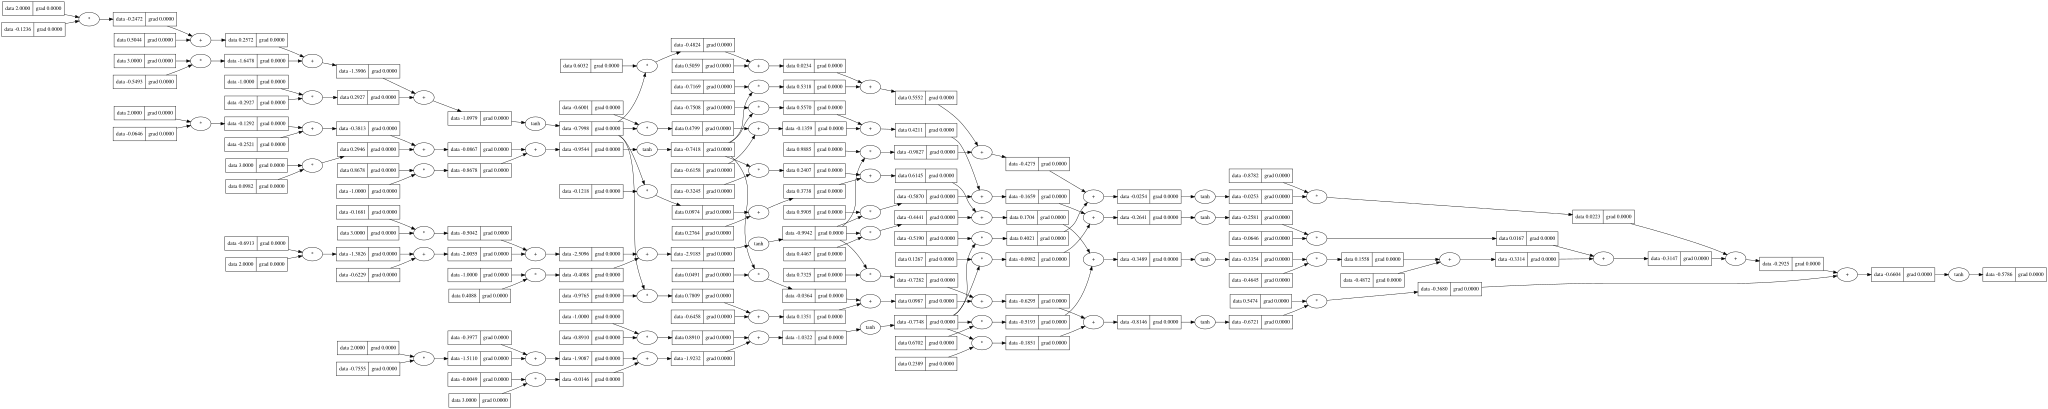

In [48]:
draw_dot(n(x))

In [147]:
# Verify the input length we are passing to the MLP
print(f"Number of inputs in x: {len(x)}")
print(f"Inputs: {x}")

# Let's inspect the weights of the very first layer's first neuron to confirm it has 3 weights (one for each input)
first_neuron = n.layers[0].neurons[0]
print(f"Number of weights in the first neuron: {len(first_neuron.w)}")

Number of inputs in x: 3
Inputs: [2.0, 3.0, -1.0]
Number of weights in the first neuron: 3


### Creating an Example Dataset, Ground Truth (ys), and Predictions (ypred)

To train our MLP, we need a small dataset of inputs (`xs`) and their corresponding target values (`ys`). We can then evaluate our network on all inputs to calculate predictions (`ypred`).

In [148]:
# Define 4 example data points, each containing 3 input features
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0]
]

# Define the ground truth target labels for each of the 4 inputs
ys = [1.0, -1.0, -1.0, 1.0]

# Display the ground truths and predictions
print("Ground Truths (ys):", ys)
print("Predictions (ypred):", ypred)

Ground Truths (ys): [1.0, -1.0, -1.0, 1.0]
Predictions (ypred): [Value(data=1.0), Value(data=1.0), Value(data=1.0), Value(data=1.0)]


Defining loss and forward pass

In [130]:
# Compute predicted outputs (ypred) by passing each input through our MLP
ypred = [n(x) for x in xs]
Loss=sum([(yout-ygt)**2 for ygt, yout in zip(ys, ypred)]) #mean squared error
print(Loss)

Value(data=7.999999999823043)


flushing the grad each time through zero grad ( making all grads zero )

In [131]:
 p.grad = 0.0

Backpropagation

In [132]:
Loss.backward()

In [133]:
n.layers[0].neurons[0].w[0].grad

-3400.4225490443796

In [134]:
n.layers[0].neurons[0].w[0].data

-34.812762891650785

In [135]:
for p in n.parameters():
    p.data += 0.01 * p.grad

In [136]:
ypred


[Value(data=0.9999999999849393),
 Value(data=0.9999999999778802),
 Value(data=0.9999999999778802),
 Value(data=0.9999999999849393)]

Multiple training loops

In [161]:
for k in range(20):
    # 1. Forward pass: compute predictions and loss
    ypred = [n(x) for x in xs]
    Loss = sum([(yout - ygt) ** 2 for ygt, yout in zip(ys, ypred)])

    # 2. Zero out gradients from the previous step
    for p in n.parameters():
        p.grad = 0.0

    # 3. Backward pass: compute gradients once
    Loss.backward()

    # 4. Update parameters using gradient descent # loss minimisation takes place here
    for p in n.parameters():
        p.data -= 0.05 * p.grad  # Subtract because we want to minimize loss

    print(k, Loss.data)

0 0.005581396713699669
1 0.00552604976975452
2 0.0054717674108662115
3 0.00541851949351549
4 0.005366276994371836
5 0.005315011958995409
6 0.0052646974533203965
7 0.005215307517746896
8 0.005166817123678818
9 0.005119202132358317
10 0.005072439255856631
11 0.005026506020090997
12 0.004981380729746595
13 0.004937042434990317
14 0.004893470899870626
15 0.0048506465723052875
16 0.004808550555564933
17 0.0047671645811662375
18 0.004726470983094615
19 0.00468645267328109


In [162]:
ypred

[Value(data=0.9628328885807182),
 Value(data=-0.9636838666971921),
 Value(data=-0.9656313225915003),
 Value(data=0.9716276370890446)]